In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split as tts
from sklearn.datasets import make_circles

In [2]:
np.random.seed(42)

In [3]:
X,y = make_circles(n_samples=500,factor=0.1,noise=0.35,random_state=42)

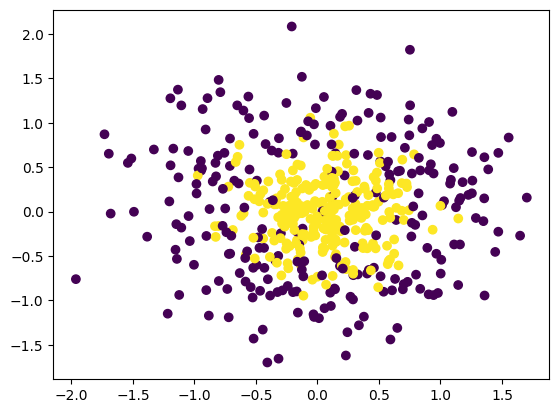

In [4]:
plt.scatter(X[:,0], X[:,1], c=y)

In [5]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score
abc = AdaBoostClassifier()
np.mean(cross_val_score(abc, X,y,scoring='accuracy', cv=10))

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\dell\an

0.786

In [6]:
abc.fit(X,y)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoostClassifier()

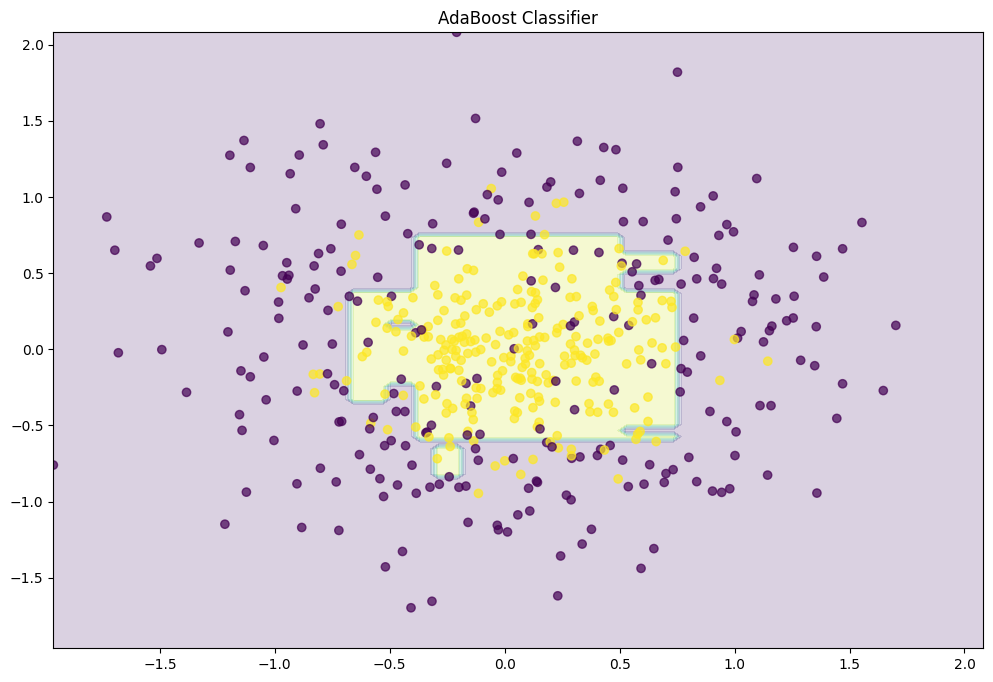

In [9]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12,8))
    x_range=np.linspace(X.min(), X.max(),100)
    xx1,xx2=np.meshgrid(x_range,x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1,xx2,y_hat,alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=0.7)
    plt.title('AdaBoost Classifier')
    plt.show()
plot_decision_boundary(abc)

<Axes: >

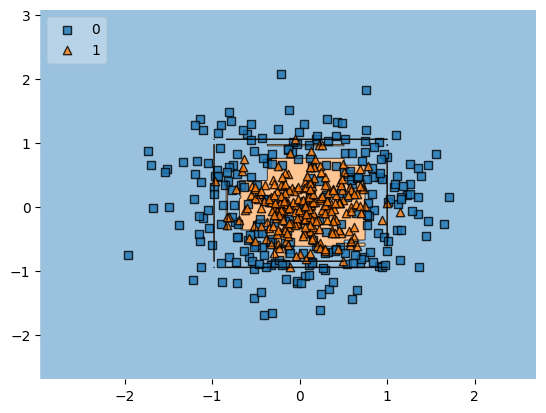

In [11]:
plot_decision_regions(X,y,clf=abc, legend=2)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


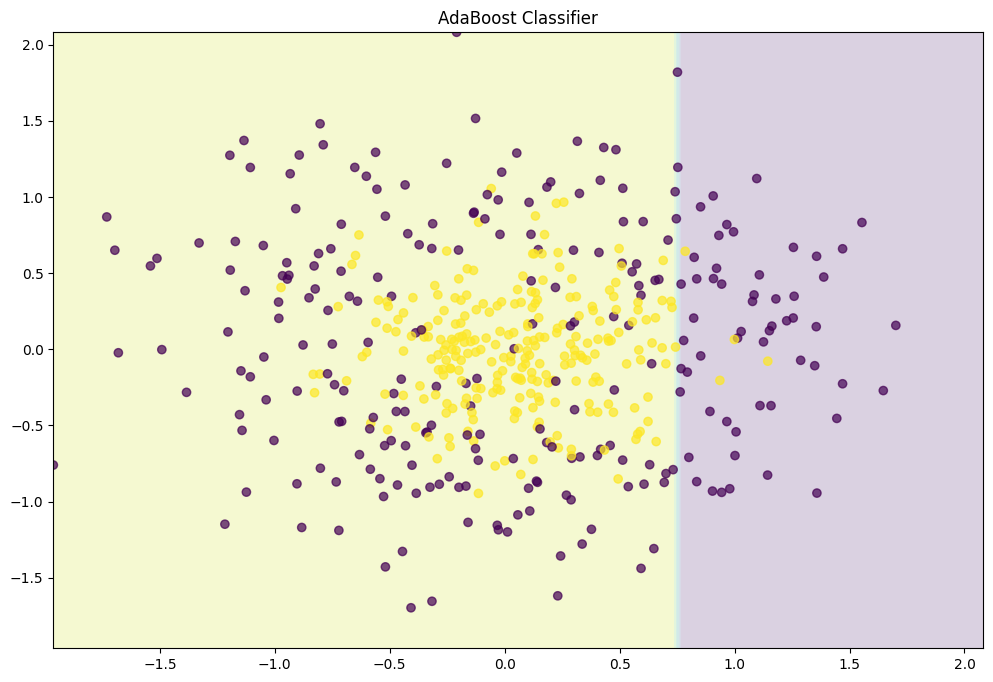

In [12]:
abc = AdaBoostClassifier(n_estimators=1)
abc.fit(X,y)
plot_decision_boundary(abc)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


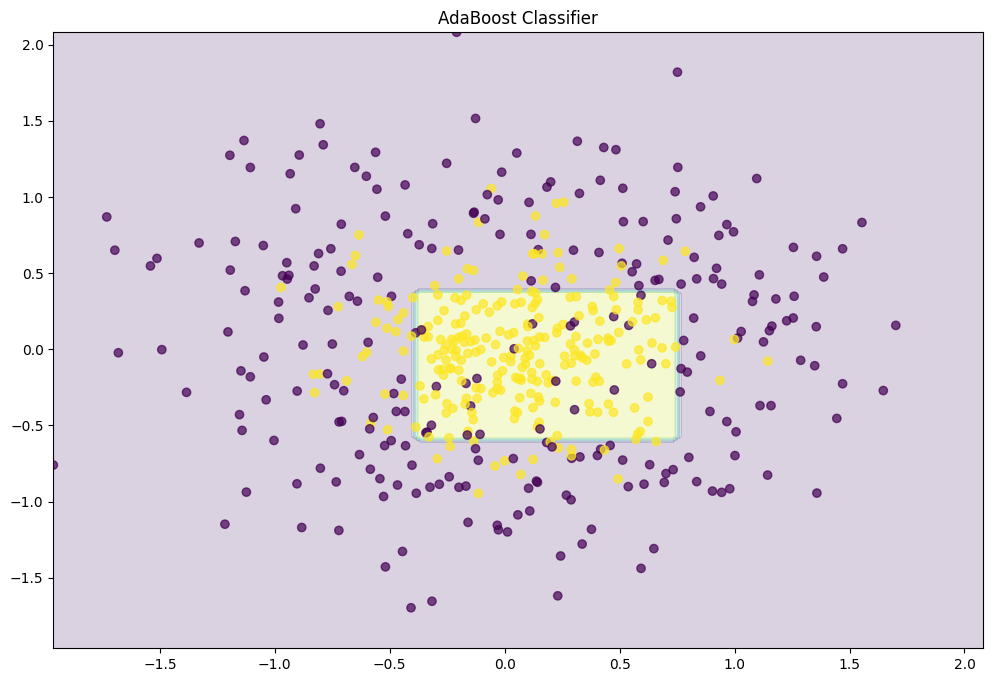

In [13]:
abc = AdaBoostClassifier(n_estimators=5)
abc.fit(X,y)
plot_decision_boundary(abc)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


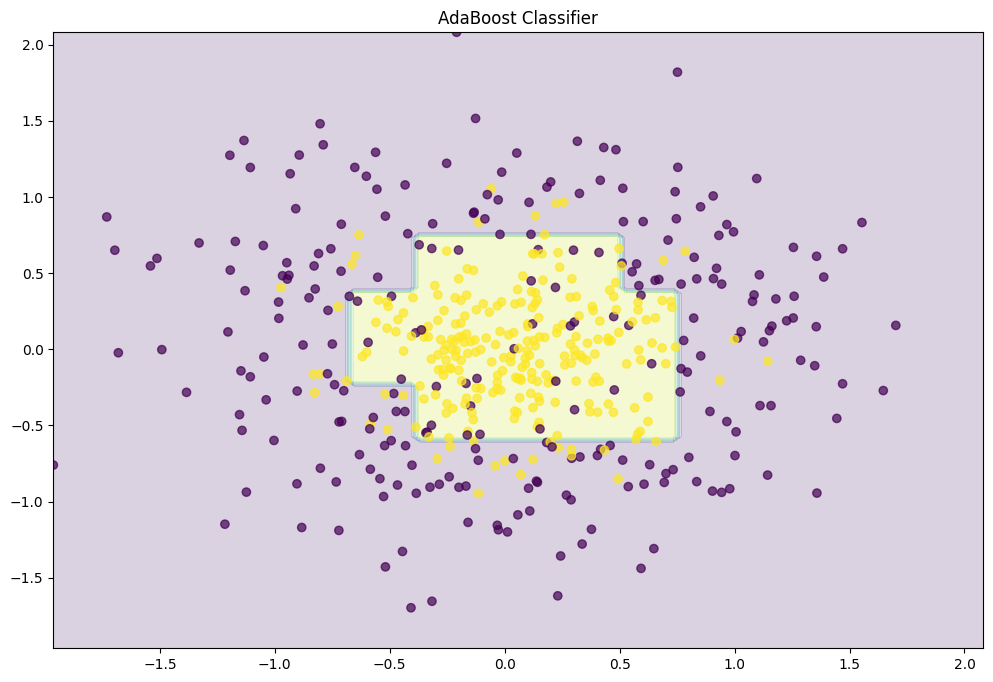

In [14]:
abc = AdaBoostClassifier(n_estimators=10)
abc.fit(X,y)
plot_decision_boundary(abc)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


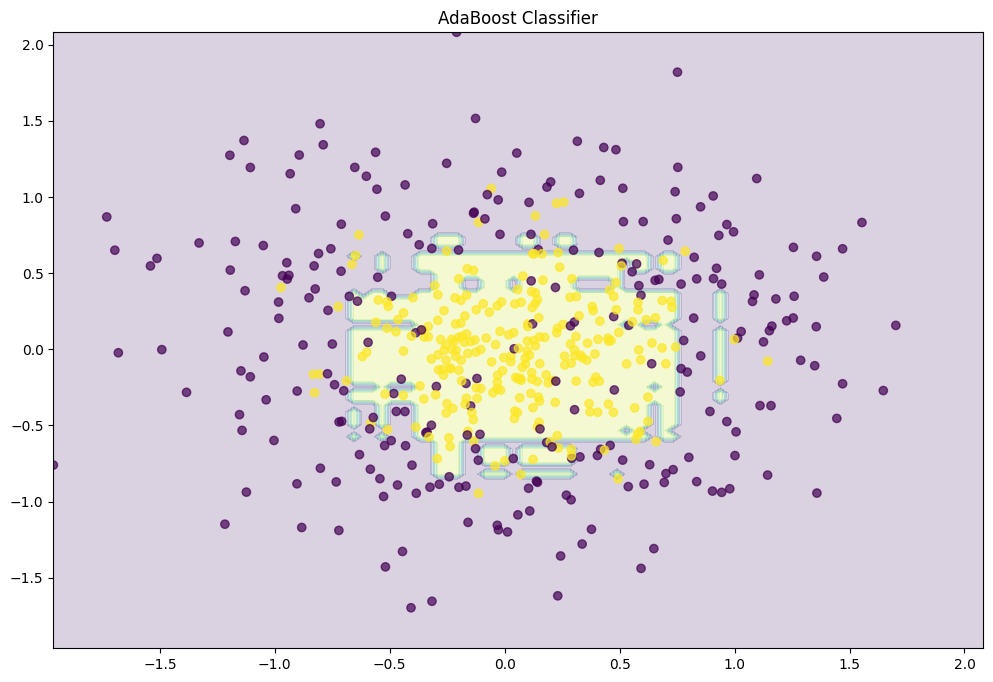

In [15]:
abc = AdaBoostClassifier(n_estimators=200)
abc.fit(X,y)
plot_decision_boundary(abc)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


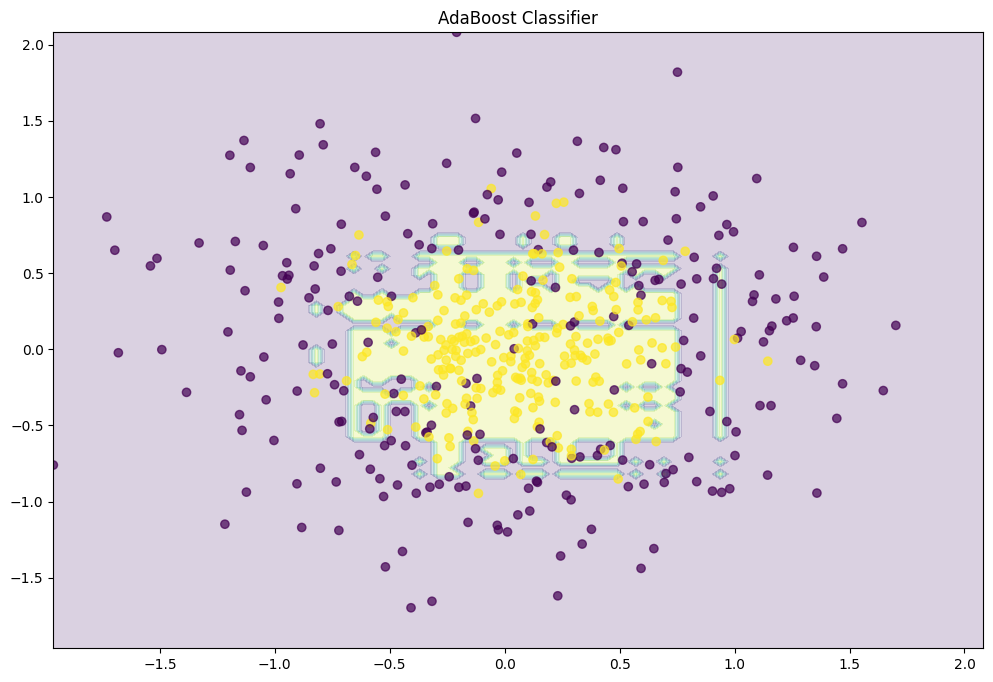

In [16]:
abc = AdaBoostClassifier(n_estimators=1000)
abc.fit(X,y)
plot_decision_boundary(abc)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


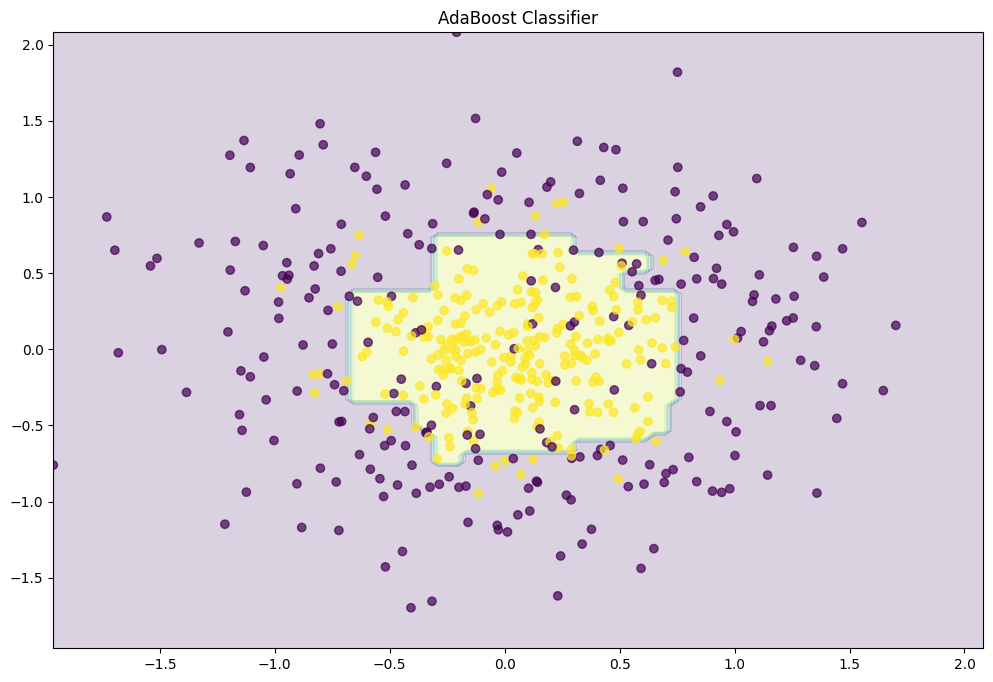

In [18]:
abc = AdaBoostClassifier(n_estimators=1000, learning_rate=0.05)
abc.fit(X,y)
plot_decision_boundary(abc)

In [19]:
from sklearn.model_selection import GridSearchCV
grid = dict()
grid['n_estimators'] = [10,50,100,500]
grid['learning_rate'] = [0.0001,0.001,0.01,0.1,1.0]
grid['algorithm'] = ['SAMME', 'SAMME.R']

grid_search = GridSearchCV(estimator=AdaBoostClassifier(),
                          param_grid=grid,
                          n_jobs=-1,
                          cv=10,
                          scoring='accuracy')
grid_result = grid_search.fit(X,y)
print("Best : %f using %s"%(grid_result.best_score_,grid_result.best_params_))

Best : 0.832000 using {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 500}
